In [195]:
# # Install dependencies as needed:
# python -m pip install pandas matplotlib seaborn jupyter
# pip install kagglehub[pandas-datasets]
import pandas as pd
%matplotlib
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn as sns
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_selector
from sklearn.compose import make_column_transformer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score
from sklearn import metrics
from sklearn.metrics import confusion_matrix



Using matplotlib backend: module://matplotlib_inline.backend_inline


In [204]:
url = "https://storage.googleapis.com/streamlit15102026/bq-results-20261015-131544-1792063003479"
df = pd.read_csv(url)#compression=gzip
display(df.head())

,NUM_POSTE,NOM_USUEL,LAT,LON,ALTI,RR,AAAAMMJJ
0,75107005,TOUR EIFFEL,48.858333,2.294500,330,NaN,20250101
1,75116008,LONGCHAMP,48.854833,2.233667,27,14.0,20250101
2,75114007,PARIS-MONTSOURIS-DOUBLE,48.821667,2.337833,75,NaN,20250101
3,75106001,LUXEMBOURG,48.844833,2.338500,50,13.3,20250101
4,75114001,PARIS-MONTSOURIS,48.821667,2.337833,75,12.9,20250101


In [205]:
df.dropna()

,NUM_POSTE,NOM_USUEL,LAT,LON,ALTI,RR,AAAAMMJJ
1,75116008,LONGCHAMP,48.854833,2.233667,27,14.0,20250101
3,75106001,LUXEMBOURG,48.844833,2.338500,50,13.3,20250101
4,75114001,PARIS-MONTSOURIS,48.821667,2.337833,75,12.9,20250101
5,75110001,LARIBOISIERE,48.882833,2.352000,55,15.3,20250101
6,75106001,LUXEMBOURG,48.844833,2.338500,50,7.4,20250102
...,...,...,...,...,...,...,...
3894,75116008,LONGCHAMP,48.854833,2.233667,27,0.2,20261012
3895,75106001,LUXEMBOURG,48.844833,2.338500,50,0.6,20261013
3897,75114001,PARIS-MONTSOURIS,48.821667,2.337833,75,0.0,20261013
3898,75110001,LARIBOISIERE,48.882833,2.352000,55,0.0,20261013


In [ ]:
# from sklearn.impute import SimpleImputer
# imputer = SimpleImputer(strategy="median")
# imputer.fit(df[['RR']])
# # df['RR'] = imputer.transform(df[['RR']])

In [207]:
df.head(5)

,NUM_POSTE,NOM_USUEL,LAT,LON,ALTI,RR,AAAAMMJJ
0,75107005,TOUR EIFFEL,48.858333,2.294500,330,0.0,20250101
1,75116008,LONGCHAMP,48.854833,2.233667,27,14.0,20250101
2,75114007,PARIS-MONTSOURIS-DOUBLE,48.821667,2.337833,75,0.0,20250101
3,75106001,LUXEMBOURG,48.844833,2.338500,50,13.3,20250101
4,75114001,PARIS-MONTSOURIS,48.821667,2.337833,75,12.9,20250101


In [ ]:
# import requests
# url = "https://storage.googleapis.com/streamlit15102026/bq-results-20261015-123241-1792060374802"
# response = requests.get(url, timeout=30)

# print(response.status_code)
# print(response.headers.get("Content-Type"))

# display(df.head())


# from io import BytesIO
# import requests
# r = requests.get(url)

# url = https://www.data.gouv.fr/datasets/donnees-climatologiques-de-base-mensuelles/api/resources/5c2d02bc-da05-434a-a274-ff4953f74e50/data/json/
# response = requests.get(url, timeout=30)
# response.raise_for_status()

# df = pd.read_csv(BytesIO(response.content), sep=";", compression="gzip")
# df.head()

In [ ]:
# response.headers.get("Content-Type")

'application/octet-stream'

In [ ]:
# response.text[:200]

'\x1f�\x08\x00\x00\x00\x00\x00\x00\x00��K�mGr��F�\x01�[�w�i��t)��\x02\x1f�z5�Y\x08d��\x1dG����ǎ��\x7f_\x04�2�����O���Ͽ����\x7f��ӿ~����\x7f���w�}���\x7f|����~���w�}��O��_����������巟\x7f��߿��?���\x1f��|����������ߞ���~y~~�����������������\x7f�\x7f�����O��\x14�||\n����\u07bf<�\x7f�xyxx'

In [ ]:
df.shape

(3901, 6)

In [ ]:
details = (
    df.groupby("NOM_USUEL")
      .agg(
          nombre_de_postes=("NUM_POSTE", "nunique"),
          postes=("NUM_POSTE", lambda s: sorted(s.dropna().unique())),
      )
      .query("nombre_de_postes >= 1")
      .sort_values("nombre_de_postes", ascending=False)
)

display(details)

,nombre_de_postes,postes
NOM_USUEL,,
LARIBOISIERE,1,[75110001]
LONGCHAMP,1,[75116008]
LUXEMBOURG,1,[75106001]
PARIS-MONTSOURIS,1,[75114001]
PARIS-MONTSOURIS-DOUBLE,1,[75114007]
TOUR EIFFEL,1,[75107005]


In [ ]:
serie = df.query("NOM_USUEL == 75116002")
print(serie.count())

NUM_POSTE    0
NOM_USUEL    0
LAT          0
LON          0
ALTI         0
AAAAMMJJ     0
dtype: int64


In [ ]:
df.shape

(3901, 6)

In [ ]:
s = df[["NOM_USUEL", "AAAAMMJJ"]]

doublons = s.duplicated()
print("Nombre de lignes en doublon :", doublons.sum())

s[doublons]

Nombre de lignes en doublon : 0


,NOM_USUEL,AAAAMMJJ


In [ ]:
station_id = "PARIS-MONTSOURIS"  # Exemple : station d'ANGLEFORT

serie = df.loc[
    df["NOM_USUEL"] == station_id,
    ["AAAAMMJJ", "RR"],
].copy()

serie["ds"] = pd.to_datetime(
    serie["AAAAMMJJ"].astype(str),
    format="%Y%m%d"
)

serie = (
    serie.rename(columns={"RR": "y"})
    [["ds", "y"]]
    .dropna()
    .sort_values("ds")
    .reset_index(drop=True)
)

serie.head()

KeyError: "['RR'] not in index"

In [ ]:
# # Install dependencies as needed:
# python -m pip install pandas matplotlib seaborn jupyter
# pip install kagglehub[pandas-datasets]
import pandas as pd
%matplotlib
import matplotlib as mpl
import seaborn as sns
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_selector
from sklearn.compose import make_column_transformer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score
from sklearn import metrics
from sklearn.metrics import confusion_matrix



Using matplotlib backend: module://matplotlib_inline.backend_inline


In [ ]:
X = serie["ds"]
y = serie["y"]

In [ ]:
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

In [ ]:
print("Cibles manquantes :", y.isna().sum())

Cibles manquantes : 0


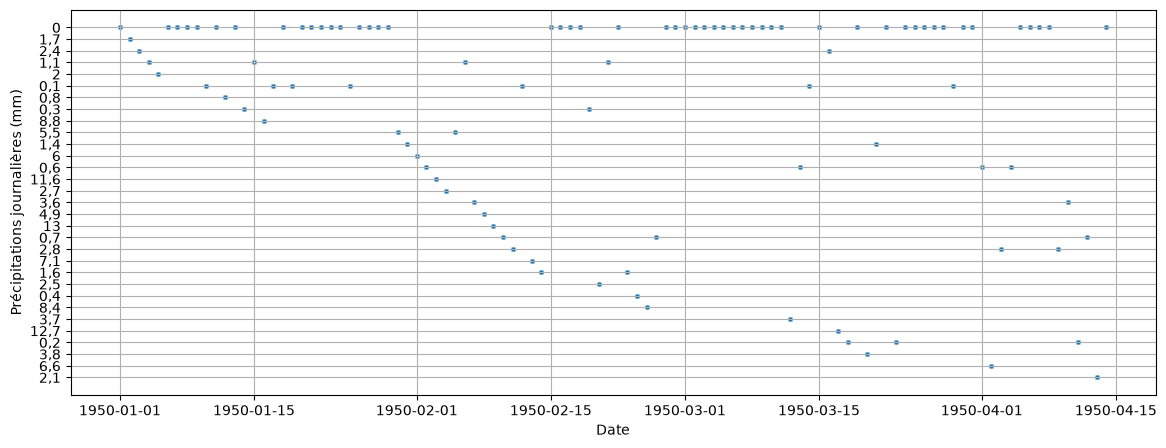

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))

sns.scatterplot(
    data=serie,
    x="ds",
    y="y",
    alpha=0.5,
    s=12,
    ax=ax,
)

ax.set_xlabel("Date")
ax.set_ylabel("Précipitations journalières (mm)")
ax.grid(True)
plt.show()

In [ ]:
print(serie[["ds", "y"]].tail())
print("Observations :", len(serie))
print("Période :", serie["ds"].min(), "à", serie["ds"].max())
print("X :", type(X), "| y :", type(y))

              ds  y
67073 1950-04-14  0
67074 1950-04-14  0
67075 1950-04-14  0
67076 1950-04-14  0
67077 1950-04-14  0
Observations : 67078
Période : 1950-01-01 00:00:00 à 1950-04-14 00:00:00
X : <class 'pandas.Series'> | y : <class 'pandas.Series'>


          ds  y
0 1950-01-01  0
1 1950-01-01  0
2 1950-01-01  0
3 1950-01-01  0
4 1950-01-01  0
Nombre de lignes : 67078


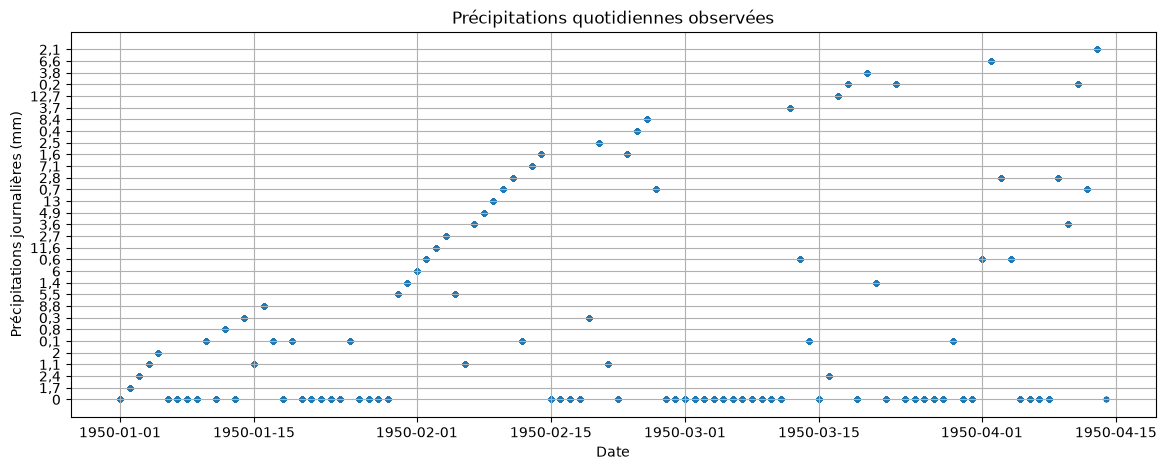

In [ ]:
import matplotlib.pyplot as plt

print(serie[["ds", "y"]].head())
print("Nombre de lignes :", len(serie))

plt.figure(figsize=(14, 5))
plt.scatter(serie["ds"], serie["y"], s=8, alpha=0.5)
plt.xlabel("Date")
plt.ylabel("Précipitations journalières (mm)")
plt.title("Précipitations quotidiennes observées")
plt.grid(True)
plt.show()

In [ ]:
from prophet import Prophet

model = Prophet()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
#python -m pip install prophet
import pandas as pd
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.plot import plot_cross_validation_metric

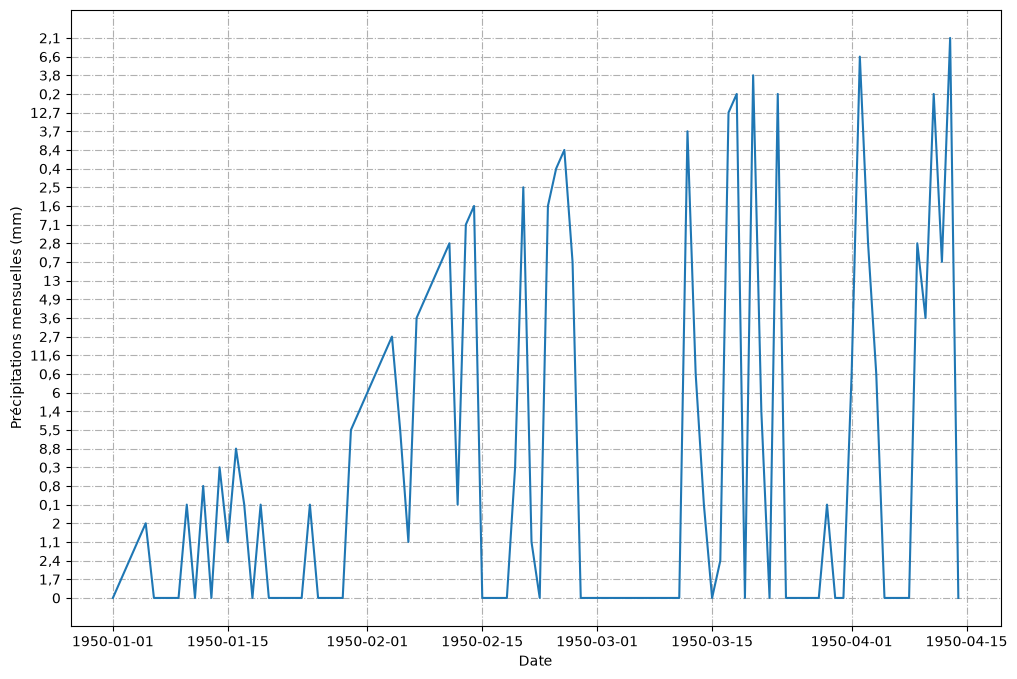

In [ ]:
plt.figure(figsize=(12, 8))
plt.grid(linestyle='-.')

plt.plot(serie["ds"], serie["y"])
plt.xlabel("Date")
plt.ylabel("Précipitations mensuelles (mm)")
plt.show()

In [ ]:
n_test = 81

train = serie.iloc[:-n_test].copy()
test = serie.iloc[-n_test:].copy()

print("Entraînement :", len(train))
print("Test :", len(test))
print("Fin de l'entraînement :", train["ds"].max())
print("Début du test :", test["ds"].min())

Entraînement : 66997
Test : 81
Fin de l'entraînement : 1950-04-13 00:00:00
Début du test : 1950-04-13 00:00:00


In [ ]:
model = Prophet(seasonality_mode='multiplicative', interval_width=0.95)
model.fit(train)

ValueError: Unable to parse string "1,7" at position 651

In [ ]:
horizon = 36  # prévoir les 36 mois qui suivent la dernière date d'entraînement

future = model.make_future_dataframe(
    periods=horizon,
    freq="MS",
)

forecast = model.predict(future)

forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(36)

,ds,yhat,yhat_lower,yhat_upper
27313,2024-11-01,2.347832,-5.184064,10.956138
27314,2024-12-01,1.968280,-6.140471,10.102421
27315,2025-01-01,2.198154,-6.447338,10.590747
27316,2025-02-01,1.988142,-5.629866,9.713033
27317,2025-03-01,1.485678,-6.639388,9.316032
27318,2025-04-01,1.850827,-6.211703,9.700599
27319,2025-05-01,2.096337,-6.348864,10.247952
27320,2025-06-01,2.575038,-5.440114,10.510512
27321,2025-07-01,2.289112,-5.269873,11.187420
27322,2025-08-01,2.064077,-5.701577,10.265268


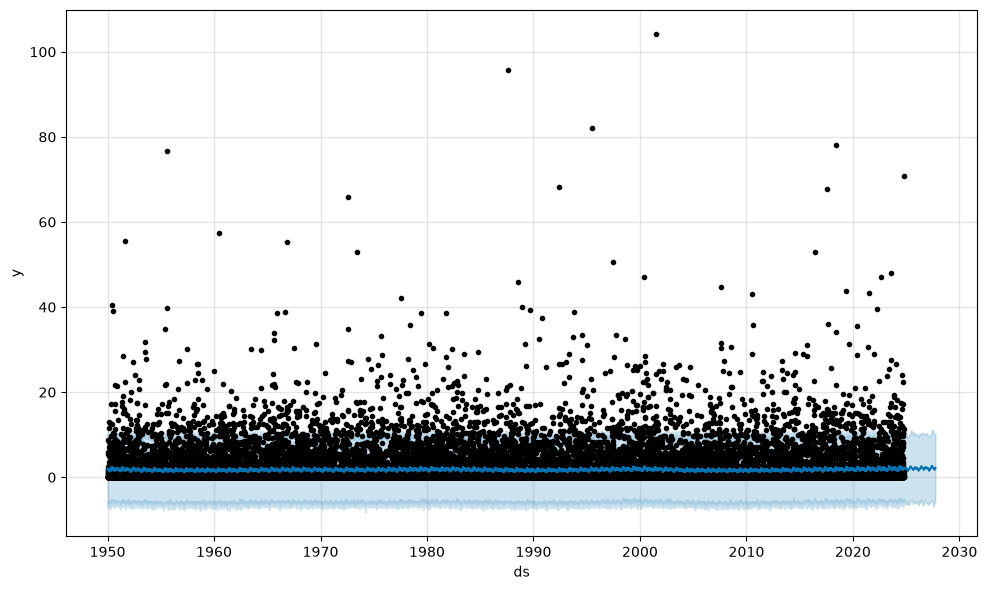

In [ ]:
ax = model.plot(forecast);

In [ ]:
cv_results = cross_validation(model=model, initial=f'{365 * 5} days', horizon='365 days', period='180 days')
cv_results

  0%|          | 0/140 [00:00<?, ?it/s]09:46:44 - cmdstanpy - INFO - Chain [1] start processing
09:46:44 - cmdstanpy - INFO - Chain [1] done processing
  1%|          | 1/140 [00:00<01:01,  2.24it/s]09:46:44 - cmdstanpy - INFO - Chain [1] start processing
09:46:45 - cmdstanpy - INFO - Chain [1] done processing
  1%|▏         | 2/140 [00:00<00:58,  2.37it/s]09:46:45 - cmdstanpy - INFO - Chain [1] start processing
09:46:45 - cmdstanpy - INFO - Chain [1] done processing
  2%|▏         | 3/140 [00:01<00:58,  2.35it/s]09:46:45 - cmdstanpy - INFO - Chain [1] start processing
09:46:45 - cmdstanpy - INFO - Chain [1] done processing
  3%|▎         | 4/140 [00:01<01:04,  2.11it/s]09:46:46 - cmdstanpy - INFO - Chain [1] start processing
09:46:46 - cmdstanpy - INFO - Chain [1] done processing
  4%|▎         | 5/140 [00:02<01:12,  1.87it/s]09:46:47 - cmdstanpy - INFO - Chain [1] start processing
09:46:47 - cmdstanpy - INFO - Chain [1] done processing
  4%|▍         | 6/140 [00:03<01:12,  1.85it/s]0

,ds,yhat,yhat_lower,yhat_upper,y,cutoff
0,1955-04-13,1.129145,-5.942719,8.920604,0.0,1955-04-12
1,1955-04-14,1.333793,-5.762828,8.951008,0.0,1955-04-12
2,1955-04-15,1.069082,-6.389187,8.251426,0.0,1955-04-12
3,1955-04-16,0.988510,-6.324593,7.827830,0.0,1955-04-12
4,1955-04-17,1.022105,-6.383423,8.172720,0.0,1955-04-12
...,...,...,...,...,...,...
51095,2024-10-07,1.686747,-6.290468,9.876579,11.3,2023-10-12
51096,2024-10-08,1.716039,-6.714573,9.588428,1.8,2023-10-12
51097,2024-10-09,1.671776,-7.439458,9.327919,70.8,2023-10-12
51098,2024-10-10,1.730046,-6.199001,9.682501,2.0,2023-10-12


In [ ]:
df_p = performance_metrics(cv_results)
df_p

,horizon,mse,rmse,mae,mdape,smape,coverage
0,37 days,18.954983,4.353732,2.461639,inf,1.527682,0.946380
1,38 days,19.290261,4.392068,2.469761,inf,1.528588,0.945988
2,39 days,19.667935,4.434855,2.483515,inf,1.527318,0.944912
3,40 days,19.557284,4.422362,2.481719,inf,1.527100,0.944618
4,41 days,19.237532,4.386061,2.469711,inf,1.524971,0.945695
...,...,...,...,...,...,...,...
324,361 days,16.035307,4.004411,2.307258,inf,1.524508,0.959980
325,362 days,15.714524,3.964155,2.300141,inf,1.522315,0.960078
326,363 days,15.702484,3.962636,2.310306,inf,1.522688,0.958806
327,364 days,14.873036,3.856558,2.296474,inf,1.522080,0.959393


In [ ]:
df_p = performance_metrics(cv_results)
df_p

,horizon,mse,rmse,mae,mdape,smape,coverage
0,37 days,18.954983,4.353732,2.461639,inf,1.527682,0.946380
1,38 days,19.290261,4.392068,2.469761,inf,1.528588,0.945988
2,39 days,19.667935,4.434855,2.483515,inf,1.527318,0.944912
3,40 days,19.557284,4.422362,2.481719,inf,1.527100,0.944618
4,41 days,19.237532,4.386061,2.469711,inf,1.524971,0.945695
...,...,...,...,...,...,...,...
324,361 days,16.035307,4.004411,2.307258,inf,1.524508,0.959980
325,362 days,15.714524,3.964155,2.300141,inf,1.522315,0.960078
326,363 days,15.702484,3.962636,2.310306,inf,1.522688,0.958806
327,364 days,14.873036,3.856558,2.296474,inf,1.522080,0.959393


In [ ]:
from prophet.plot import plot_cross_validation_metric


In [ ]:
forecast_test = model.predict(test[["ds"]])

resultats = test.merge(
    forecast_test[["ds", "yhat"]],
    on="ds",
)

from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

mse = mean_squared_error(resultats["y"], resultats["yhat"])
rmse = np.sqrt(mse)
mae = mean_absolute_error(resultats["y"], resultats["yhat"])

print(f"MSE  : {mse:.2f} mm²")
print(f"RMSE : {rmse:.2f} mm")
print(f"MAE  : {mae:.2f} mm")

MSE  : 18.14 mm²
RMSE : 4.26 mm
MAE  : 2.75 mm


In [ ]:
display(resultats[["ds", "y", "yhat"]].tail(10))

,ds,y,yhat
71,2024-12-22,8.5,2.264277
72,2024-12-23,1.2,2.235628
73,2024-12-24,0.6,2.279954
74,2024-12-25,0.2,2.274102
75,2024-12-26,0.0,2.319309
76,2024-12-27,0.0,2.234124
77,2024-12-28,0.0,2.207456
78,2024-12-29,0.0,2.229185
79,2024-12-30,0.0,2.186918
80,2024-12-31,0.0,2.217588


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

prediction_zero = np.zeros(len(resultats))

print("MAE référence zéro :", mean_absolute_error(resultats["y"], prediction_zero))
print("RMSE référence zéro :", np.sqrt(mean_squared_error(resultats["y"], prediction_zero)))

MAE référence zéro : 1.8592592592592596
RMSE référence zéro : 4.616743547962603


In [ ]:
print("Part des jours sans pluie :", (resultats["y"] == 0).mean())


Part des jours sans pluie : 0.3950617283950617


In [ ]:
jours_secs = resultats["y"] == 0
jours_pluvieux = resultats["y"] > 0

print("MAE les jours secs :", mean_absolute_error(
    resultats.loc[jours_secs, "y"],
    resultats.loc[jours_secs, "yhat"],
))

print("MAE les jours pluvieux :", mean_absolute_error(
    resultats.loc[jours_pluvieux, "y"],
    resultats.loc[jours_pluvieux, "yhat"],
))

MAE les jours secs : 2.1548599768272507
MAE les jours pluvieux : 3.1413695174653715


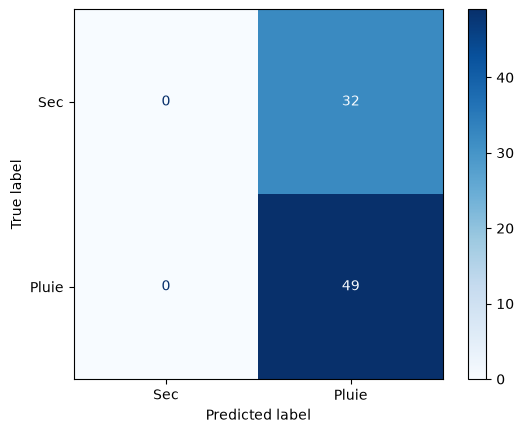

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Observations réelles et prédictions transformées en catégories
pluie_observee = resultats["y"] > 0
pluie_predite = resultats["yhat"] > 0

cm = confusion_matrix(
    pluie_observee,
    pluie_predite,
    labels=[False, True],
)

affichage = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Sec", "Pluie"],
)

affichage.plot(cmap="Blues", values_format="d")
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)

precision = precision_score(
    pluie_observee, pluie_predite, zero_division=0
)
recall = recall_score(
    pluie_observee, pluie_predite, zero_division=0
)
f1 = f1_score(
    pluie_observee, pluie_predite, zero_division=0
)
accuracy = accuracy_score(pluie_observee, pluie_predite)

print(f"Précision (Precision) : {precision:.3f} ({precision:.1%})")
print(f"Rappel (Recall)       : {recall:.3f} ({recall:.1%})")
print(f"F1-score              : {f1:.3f} ({f1:.1%})")
print(f"Accuracy              : {accuracy:.3f} ({accuracy:.1%})")

Précision (Precision) : 0.605 (60.5%)
Rappel (Recall)       : 1.000 (100.0%)
F1-score              : 0.754 (75.4%)
Accuracy              : 0.605 (60.5%)


In [ ]:
import pandas as pd
from prophet import Prophet

# Pour la prévision finale, utilise toutes les observations disponibles
model = Prophet()
model.fit(serie[["ds", "y"]])

aujourd_hui = pd.Timestamp.today().normalize()
date_cible = aujourd_hui + pd.DateOffset(years=1)

derniere_observation = serie["ds"].max()
horizon_jours = (date_cible - derniere_observation).days

future = model.make_future_dataframe(
    periods=horizon_jours,
    freq="D",
)

forecast = model.predict(future)

# Afficher les prévisions entre aujourd'hui et un an après
previsions_a_venir = forecast.loc[
    forecast["ds"].between(aujourd_hui, date_cible),
    ["ds", "yhat", "yhat_lower", "yhat_upper"],
]

display(previsions_a_venir.head())
display(previsions_a_venir.tail())

09:55:32 - cmdstanpy - INFO - Chain [1] start processing
09:55:40 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
28046,2026-10-15,2.095056,-2.934557,7.223688
28047,2026-10-16,2.037508,-3.239719,7.323111
28048,2026-10-17,2.043941,-3.406486,7.270316
28049,2026-10-18,2.095707,-3.520132,7.345868
28050,2026-10-19,2.099823,-3.520152,7.499241


,ds,yhat,yhat_lower,yhat_upper
28407,2027-10-11,2.007899,-3.374226,7.279559
28408,2027-10-12,2.044795,-3.190629,7.344112
28409,2027-10-13,2.047257,-3.055627,7.159505
28410,2027-10-14,2.108145,-3.558361,7.131083
28411,2027-10-15,2.046533,-3.485423,7.422839


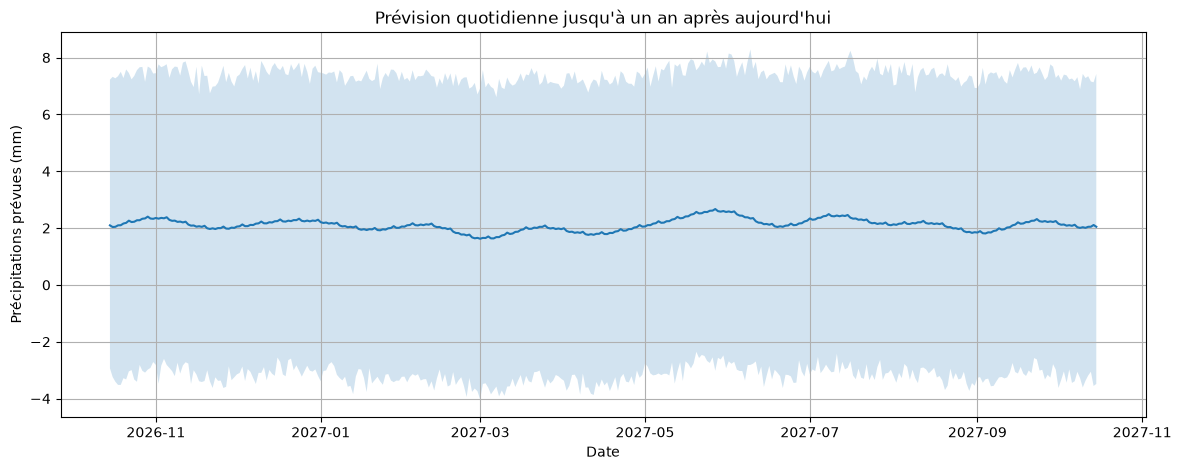

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(previsions_a_venir["ds"], previsions_a_venir["yhat"])
plt.fill_between(
    previsions_a_venir["ds"],
    previsions_a_venir["yhat_lower"],
    previsions_a_venir["yhat_upper"],
    alpha=0.2,
)
plt.xlabel("Date")
plt.ylabel("Précipitations prévues (mm)")
plt.title("Prévision quotidienne jusqu'à un an après aujourd'hui")
plt.grid(True)
plt.show()

In [ ]:
station_id = 'PARIS-MONTSOURIS'  # remplace par le poste choisi

new_datapoint = pd.DataFrame({
    "NOM_USUEL": [station_id],
    "ds": [pd.Timestamp("2027-06-17")],
})

prediction = model.predict(new_datapoint[["ds"]])

prediction.insert(0, "NUM_POSTE", station_id)
display(prediction[["NUM_POSTE", "ds", "yhat", "yhat_lower", "yhat_upper"]])

,NUM_POSTE,ds,yhat,yhat_lower,yhat_upper
0,PARIS-MONTSOURIS,2027-06-17,2.150253,-3.058456,7.432428


In [ ]:
import builtins

pluie_estimee = prediction["yhat"].iloc[0]
date_prevue = prediction["ds"].iloc[0]

builtins.print(
    f"Pour le {date_prevue:%d/%m/%Y}, la pluie estimée est "
    f"{pluie_estimee:.2f} mm."
)

Pour le 17/06/2027, la pluie estimée est 2.15 mm.


In [ ]:
import joblib

In [ ]:
import joblib

joblib.dump(
    {
        "preprocessor": future,
        "model": model,
    },
    "weather_artifacts.joblib",
)

['weather_artifacts.joblib']

In [ ]:
artifacts = joblib.load("weather_artifacts.joblib")

future = artifacts["preprocessor"]
model = artifacts["model"]

In [ ]:
csv_path2 = '/home/matthieumouillon/projects/app-streamlit/streamlit/Modèle/Data/Q_75_latest-2025-2026_RR-T-Vent.csv'
df2 = pd.read_csv(csv_path2, sep=";", encoding="utf-8-sig")

In [ ]:
df2.head(1)

,NUM_POSTE,NOM_USUEL,LAT,LON,ALTI,AAAAMMJJ,RR,QRR,TN,QTN,...,FXI3S,QFXI3S,DXI3S,QDXI3S,HXI3S,QHXI3S,DRR,QDRR,STATUS_FXI3S,STATUS_DXI3S
0,75106001,LUXEMBOURG,48.844833,2.3385,50,20250101,13.3,1.0,4.6,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


: 